In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.harmonicImplicit import poissonSurface
from implicitSurfaces.sdf_primitives import sphere_sdf, bbox_sdf, arc2d
from sphereWalker.integrator import WoSIntegrator, DifferentialWoSIntegrator
from sphereWalker.sampling import sample_uniform_1sphere
from utils.losses import volume_integral_loss_grad, surface_integral_loss_grad, l2_loss, dL2_du
from utils.tree_ops import binary_tree_op
import operator
from utils.helpers import mesh_2d

/system/user/volkmann/jax_playground/implicitSurfaces/harmonicImplicit.py:76: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  f(x) = c + \sum_i a_i * (1 / ||x - p_i||)


In [3]:
jax.config.update("jax_debug_nans", True)

In [16]:
def smily_sdf(params, x):
    outer_boundary = bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x)
    left_eye = sphere_sdf({'center': jnp.array([-0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    right_eye = sphere_sdf({'center': jnp.array([0.5, 0.5]), 'radius': jnp.array(0.2)}, x)
    tb = 3.14 * (0.25 + 0.5 * 0.1)
    mouth = arc2d({'sc': jnp.array([jnp.sin(tb), jnp.cos(tb)]), 'ra': jnp.array(0.65), 'rb': jnp.array(0.12)}, -x)
    eyes_and_mouth = jnp.minimum(jnp.minimum(left_eye, right_eye), mouth)
    return jnp.maximum(outer_boundary, -eyes_and_mouth)


In [17]:
bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, jnp.array([0., 0.]))

Array(-0.999999, dtype=float32)

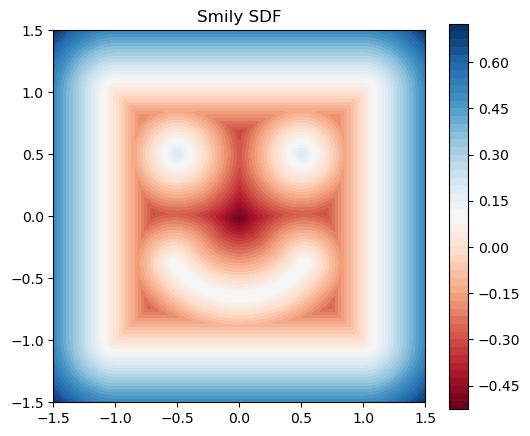

In [18]:
X, Y = mesh_2d(128, ((-1.5, 1.5), (-1.5, 1.5)))
points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)
contouf = ax.contourf(X, Y, jax.vmap(smily_sdf)(None, points).reshape(X.shape), levels=50, cmap='RdBu')
ax.set_aspect('equal')
ax.set_title('Smily SDF')
plt.colorbar(contouf)
plt.show()

In [19]:
to_opt_surface = poissonSurface(level_set=25., alpha=1.25, dim=2, scale=0.5, offset=0.)
surface_params = to_opt_surface.init_monopole_field(jr.PRNGKey(0), bbox=((-0.5, 0.5), (-0.5, 0.5)), num_points=25)
to_opt_params = surface_params

In [20]:
fn_vals = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape)
fn_vals.min(), fn_vals.max()

(Array(5.9768295, dtype=float32), Array(128.18213, dtype=float32))

/tmp/ipykernel_3518488/2804805179.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')


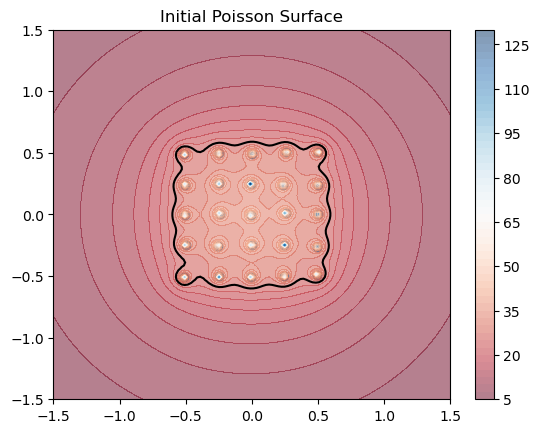

In [21]:
plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')
contouf = plt.contourf(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=50, cmap='RdBu', alpha=0.5)
contour = plt.contour(X, Y, jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, points).reshape(X.shape), levels=[to_opt_surface.level_set], colors='black')
plt.colorbar(contouf)
plt.title('Initial Poisson Surface')
plt.show()

In [22]:
def const_source_fn(x):
    return 4.0

def zero_boundary_condition(point: jnp.ndarray) -> jnp.ndarray:
    return 0.0

In [23]:
X, Y = mesh_2d(512, ((-1.5, 1.5), (-1.5, 1.5)))
opt_loop_points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)
inside_reference_mask = jax.vmap(smily_sdf)(None, opt_loop_points) < 0

In [24]:
key = jax.random.PRNGKey(0)
N = 10000
reference_surface = sdfImplicit(fn=smily_sdf, dim=2)

reference_solver = WoSIntegrator(
    empty_sphere_fn=reference_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

reference_estimate = reference_solver.integrate_batch(None, opt_loop_points[inside_reference_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
reference_estimate_full = jnp.zeros((opt_loop_points.shape[0], 1))
reference_estimate_full = reference_estimate_full.at[inside_reference_mask].set(reference_estimate.w)


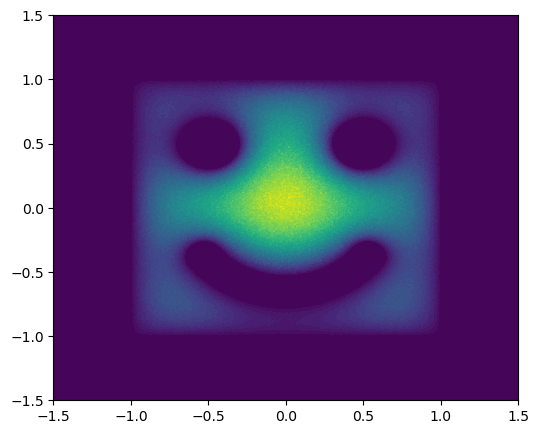

In [25]:
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111)

contouf = ax.contourf(X, Y, reference_estimate_full.squeeze().reshape(X.shape), levels=50)
#ax.scatter(opt_loop_points[inside_reference_mask, 0], opt_loop_points[inside_reference_mask, 1])

In [26]:
def sgd_step(params, opt_state, grads, optimizer):
    updates, new_opt_state = optimizer.update(grads, opt_state)
    params_new = optax.apply_updates(params, updates)
    return params_new, new_opt_state

In [27]:
outer_surf = sdfImplicit(fn=lambda params, x: bbox_sdf({'min_corner': jnp.array([-1., -1.]), 'max_corner': jnp.array([1., 1.])}, x), dim=2)

def joint_es_fn(params, x, tr_size):
    fn_val1, es1, tr_update1 = to_opt_surface.empty_sphere(params, x, tr_size)
    fn_val2, es2, tr_update2 = outer_surf.empty_sphere(params, x, tr_size)
    es = jnp.where(es1 < es2, es1, es2)
    fn_val = jnp.where(es1 < es2, fn_val1, fn_val2 + to_opt_surface.level_set)
    tr_update = jnp.where(es1 < es2, tr_update1, tr_update2)
    return fn_val, es, tr_update
    
    #return fn_val2 + to_opt_surface.level_set, es2, tr_update2

dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=joint_es_fn, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=to_opt_surface.dirichlet_boundary_differential,
    V_n=to_opt_surface.normal_surface_velocity,
    normal_fn=to_opt_surface.normal_at,
    offset_l=0.01,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-1,
    max_steps=1000,
)

primary_integrator = WoSIntegrator(
    empty_sphere_fn=joint_es_fn, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=to_opt_surface.dim,
    level_set=to_opt_surface.level_set,
    eps=1e-1,
    max_steps=1000,
    print_progress=False
)


optimizer = optax.sgd(learning_rate=1e0, momentum=0.9)
opt_state = optimizer.init(to_opt_params)

In [29]:
for i in range(10):
    field = jax.vmap(to_opt_surface, in_axes=(None, 0))(to_opt_params, opt_loop_points)
    field_grad_norm = jnp.linalg.norm(jax.vmap(to_opt_surface.spatial_derivative, in_axes=(None, 0))(to_opt_params, opt_loop_points), axis=-1)
    inside_both_mask = jnp.logical_and(inside_reference_mask, field < to_opt_surface.level_set)
    close_to_surface_mask = jnp.logical_and(inside_reference_mask, (field - to_opt_surface.level_set) < 1e-1)

    primary_estimate = primary_integrator.integrate_batch(to_opt_params, opt_loop_points[inside_both_mask], rng_key=jax.random.PRNGKey(-i), init_trust_region_size=jnp.inf, n_samples=10, steps_between_refill=100)
    dif_estimate = dif_integrator.integrate_batch(to_opt_params, opt_loop_points[inside_both_mask], rng_key=jax.random.PRNGKey(i), init_trust_region_size=jnp.inf, n_samples=10, steps_between_refill=100)

    def add_surface_grad_fn(grads, params, surf_mask):
        sol_estimate = jax.vmap(zero_boundary_condition)(opt_loop_points)
        Vn = jax.vmap(to_opt_surface.normal_surface_velocity, in_axes=(None, 0))(params, opt_loop_points)
        surf_grad = surface_integral_loss_grad(loss_fn=l2_loss,
                                               mask=surf_mask,
                                               solution_u=sol_estimate.squeeze(),
                                               solution_target=reference_estimate_full.squeeze(),
                                               normal_velocity_field=Vn)
        return binary_tree_op(operator.add, grads, surf_grad)
    
    grads = volume_integral_loss_grad(dL2_du, mask=None, 
                                      solution_u=primary_estimate.w.squeeze(),
                                      solution_target=reference_estimate_full.squeeze()[inside_both_mask],
                                      del_solution_del_theta=dif_estimate.w,)
    grads = jax.lax.cond(jnp.any(close_to_surface_mask), add_surface_grad_fn, lambda g, p, m: g, grads, surface_params, close_to_surface_mask)
    loss = l2_loss(primary_estimate.w.squeeze(), reference_estimate_full.squeeze()[inside_both_mask]).sum()
    print(f"Iter {i}, Loss: {loss}")
    surface_params, opt_state = sgd_step(surface_params, opt_state, grads, optimizer)

Iter 0, Loss: 119.78926086425781
Iter 1, Loss: 119.814453125
Iter 2, Loss: 119.654052734375
Iter 3, Loss: 119.82780456542969
Iter 4, Loss: 120.08417510986328
Iter 5, Loss: 120.15701293945312
Iter 6, Loss: 119.76248168945312
Iter 7, Loss: 119.56060791015625
Iter 8, Loss: 120.26227569580078
Iter 9, Loss: 119.75119018554688


/tmp/ipykernel_3504340/1692168891.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')


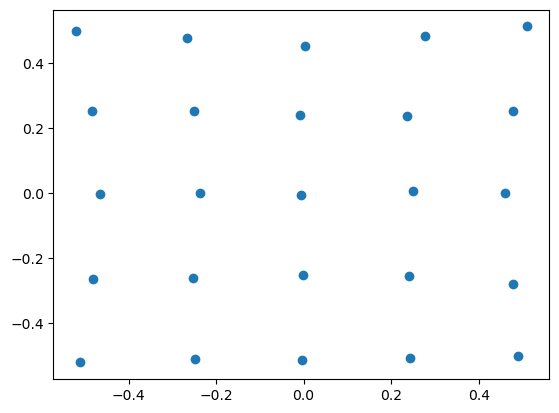

In [27]:
plt.scatter(surface_params['p'][:, 0], surface_params['p'][:, 1], cmap='viridis')